# Global Spatial Sensitivity of Runoff to Subsurface Permeability Using the Active Subspace Method

__James M. Gilbert__<sup>a</sup>, __Jennifer L. Jefferson__<sup>a</sup>, __Paul G. Constantine__<sup>b</sup> and __Reed M. Maxwell__<sup>a</sup>

<sup>a</sup> Hydrologic Science and Engineering Program, Integrated GroundWater Modeling Center, Department of Geology and Geological Engineering, Colorado School of Mines, Golden, Colorado, USA<br>
<sup>b</sup> Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, Colorado, USA

__Ryan Howard__ (2016 notebook)

<br>

This notebook summarizes the active subspace analysis of runoff from an integrated hydrologic model with random permeability fields in [[1]][R1], with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`) in one to two minutes. It uses no random numbers.

### Introduction

Overland water flow (runoff) is an important hydrologic phenomenon that drives associated processes such as erosion and contaminant transport. There are two primary mechanisms generating runoff: Dunnian (saturation excess), in which the soil is saturated and adding water forces existing water out of the soil, and Hortonian (infiltration excess), in which the rate of precipitation exceeds the rate at which the soil can absorb water. In both cases, downslope effects of upslope runoff depend on the characteristics of the intervening land and may be sensitive to heterogeneity in such properties. Here we study the relationship between accumulated runoff volume and spatially varying permeability fields with the active subspace method and the integrated hydrologic model ParFlow.

### The Integrated Hydrologic Model

ParFlow simulates surface and subsurface flow in an idealized "tilted-v" domain of 300 m × 300 m × 16 m, discretized into 30 × 30 × 16 cells of 10 m × 10 m × 1 m (14,400 cells; §2.6 and Fig. 1 of [[1]][R1]). All properties are spatially uniform except the subsurface permeability (Table 1 of [[1]][R1] lists the others). The log permeability is modeled as a Gaussian random field with mean $\mu(\mathbf s)$ and two-point correlation function $C(\mathbf s, \mathbf t)$, where $\mathbf s$ and $\mathbf t$ are points in the domain. If the correlation function has the eigenpairs

$$
\int C(\mathbf s, \mathbf t)\,\phi_i(\mathbf s)\,d\mathbf s = \sigma_i^2\,\phi_i(\mathbf t),\quad i=1,2,\dots,
$$

the field has the truncated Karhunen–Loève (KL) approximation

$$
\log\kappa(\mathbf s)\approx \mu(\mathbf s) + \sum_{i=1}^m\sigma_i\,\phi_i(\mathbf s)\,X_i,
$$

where the $X_i$ are independent standard Gaussian random variables (eqs. (7)–(10) of [[1]][R1]). The coefficients $\mathbf x = (x_1,\dots,x_m)$ are the inputs of our study: a realization of $\mathbf x$ gives a realization of the log permeability on the grid, $\log\boldsymbol\kappa = \boldsymbol\mu + \mathbf B\mathbf x$ (eq. (12)), which ParFlow then uses. In [[1]][R1] the basis $\mathbf B$ is computed empirically, not from an analytic covariance: it holds the first $m = 100$ principal components of 2,000 log permeability fields generated with a turning bands algorithm (§2.4 and Table 2: geometric mean permeability 0.04465 m h⁻¹, correlation lengths $\lambda_x = \lambda_y = 50$ m and $\lambda_z = 5$ m, chosen "from the lower end of the range"). One hundred terms were enough to reproduce the correlation lengths of the turning bands fields. The input file's name, `inputs-ShortCorr`, refers to this short correlation length.

There are two scenarios (§2.6 of [[1]][R1]), each simulated for 48 hours and each run 10,000 times with the same 10,000 inputs drawn from $\rho$, the standard Gaussian density on $\mathbb R^{100}$:

- **Hortonian** (initially unsaturated): a deep water table, at the bottom of the domain, and a 3-hour precipitation event of 5 cm/h over model hours one to three.
- **Dunnian** (initially saturated): a near-surface water table and no precipitation.

The quantity of interest $f$ is the cumulative runoff volume at the outlet over the 48 hours, in m³.

### Active Subspaces

The active subspace method identifies important directions in the input space, along which perturbations of the inputs change the output more, on average, than perturbations in the orthogonal directions ([[2]][R2], [[3]][R3]). It is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\,\nabla f(\mathbf x)^T \rho(\mathbf x)\,d\mathbf x = \mathbf W \Lambda\mathbf W^T,
$$

where $\mathbf W \Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$, with the eigenvalues in descending order on the diagonal of $\Lambda$ and the eigenvectors in the columns of $\mathbf W$. They satisfy $\int(\nabla f^T\mathbf w_i)^2\rho\,d\mathbf x = \lambda_i$: the $i$-th eigenvalue measures how much $f$ changes, on average, along $\mathbf w_i$. If the first few eigenvalues are large compared with the rest, the corresponding eigenvectors span an important subspace.

ParFlow does not give us $\nabla f$, and finite differences would cost $m+1 = 101$ simulations per gradient. So [[1]][R1] (§2.1) estimates the _single_ most important direction from the input/output pairs:

1. Draw $\{\mathbf x_i\}_{i=1}^N$ from $\rho$ (here $N = 10{,}000 = 100\,m$).
2. Compute $f_i = f(\mathbf x_i)$ for each $i$.
3. Use least squares to fit the coefficients $\hat a_0$ and $\hat{\mathbf a}$ of the linear model $f_i \approx \hat a_0 + \hat{\mathbf a}^T\mathbf x_i$.
4. $\hat{\mathbf w} = \hat{\mathbf a}/\|\hat{\mathbf a}\|$ is the estimated important direction.

For standard Gaussian inputs this has a precise meaning. By Stein's lemma [[4]][R4], $\mathbb E[\mathbf x f(\mathbf x)] = \mathbb E[\nabla f(\mathbf x)]$, so the population least-squares slope is the average gradient, and $\hat{\mathbf w}$ estimates the normalized average gradient $\mathbb E[\nabla f]/\|\mathbb E[\nabla f]\|$. That vector lies in the range of $\mathbf C$, but it need not be the first eigenvector of $\mathbf C$; the method finds only one direction, and it fails when $\mathbb E[\nabla f] \approx 0$, for example when $f$ is not monotonic. The check is the _sufficient summary plot_ of $f_i$ against the active variable $\hat{\mathbf w}^T\mathbf x_i$. The components of $\hat{\mathbf w}$ (the weights) measure sensitivity: inputs with larger-magnitude weights are more important.

The sign of $\hat{\mathbf w}$ is fixed, $\hat{\mathbf w} = \hat{\mathbf a}/\|\hat{\mathbf a}\|$, as in [[1]][R1]: "in both runoff cases, the cumulative outflow increases directly with increasing active variable" (p. 37). The v1 library returns this sign.

### The data

The files are stored data: ParFlow produced them, and they are the only record of these runs (see `DATA.md`). The inputs are the 10,000 × 100 KL coefficients, standard Gaussian, used as they are: on a standard Gaussian space the physical and normalized coordinates coincide. The outputs are the Dunnian and Hortonian runoff volumes, in m³.

- **Zero runoff.** 31% of the Hortonian runs produce no runoff at all. [[1]][R1] "filtered out the results from realizations yielding no runoff such that Fig. 7 represents only the non-zero runoff cases" (p. 37). We do the same: the Hortonian weights and summary plot below use the non-zero runs only, and the number of zero runs is printed. The files are not changed.
- **Scale of the figures in [[1]][R1].** With $\mathbf x \sim N(\mathbf 0, \mathbf I)$ and $\|\hat{\mathbf w}\| = 1$, the active variable is standard Gaussian, so its sample range is about $\pm 4$. The summary plots of [[1]][R1] (Figs. 6b, 7b) span about $\pm 1$, and their weights differ slightly from ours. Rescaling each input column to $[-1, 1]$ by its sample minimum and maximum reproduces them, so the paper's figures appear to use that scaling (inferred; the paper states the Gaussian density). We keep the Gaussian scale, which is the one the paper's $\rho$ defines, and show the comparison below. The directions agree closely, so the conclusions do not change.
- **No spatial plots.** The basis $\mathbf B$ and the grid are not in the repository, so the spatial sensitivity maps $\mathbf B\hat{\mathbf w}$ of [[1]][R1] (Figs. 8 and 9) cannot be reproduced. The weights are shown per KL coefficient only.

### References

[[1]][R1] J.M. Gilbert, J.L. Jefferson, P.G. Constantine, and R.M. Maxwell. _Global spatial sensitivity of runoff to subsurface permeability using the active subspace method_. Adv. Water Resour., 92:30–42, 2016. doi:10.1016/j.advwatres.2016.03.020

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[3]][R3] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[4]][R4] C.M. Stein. _Estimation of the mean of a multivariate normal distribution_. Ann. Statist., 9(6):1135–1151, 1981. doi:10.1214/aos/1176345632

[[5]][R5] K.-C. Li. _On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma_. J. Amer. Statist. Assoc., 87(420):1025–1039, 1992. doi:10.1080/01621459.1992.10476258

[R1]: https://doi.org/10.1016/j.advwatres.2016.03.020
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.1214/aos/1176345632
[R5]: https://doi.org/10.1080/01621459.1992.10476258

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

t_start = time.perf_counter()

We read the 10,000 inputs and the two sets of runoff volumes, and check that the inputs look like independent standard Gaussian draws.

In [2]:
X = np.loadtxt('inputs-ShortCorr.GW02.txt')        # (10000, 100) KL coefficients, standard Gaussian
f_D = np.loadtxt('RunOff02_Saturated_10k.txt')     # Dunnian (initially saturated) runoff volume [m^3]
f_H = np.loadtxt('RunOff02_Unsaturated_10k.txt')   # Hortonian (initially unsaturated) runoff volume [m^3]
M, m = X.shape
nz = f_H > 0                                       # Hortonian runs with non-zero runoff
n_zero = int(np.sum(~nz))

corr = np.corrcoef(X, rowvar=False)
print(f'inputs {X.shape}, Dunnian {f_D.shape}, Hortonian {f_H.shape}')
print(f'inputs: column means in [{X.mean(0).min():.3f}, {X.mean(0).max():.3f}], '
      f'standard deviations in [{X.std(0, ddof=1).min():.3f}, {X.std(0, ddof=1).max():.3f}], '
      f'max |off-diagonal correlation| {np.abs(corr - np.eye(m)).max():.3f}, '
      f'pooled KS test against N(0, 1): p = {stats.kstest(X.ravel(), "norm").pvalue:.2f}')
print(f'Dunnian runoff:   {f_D.min():8,.0f} to {f_D.max():6,.0f} m^3, mean {f_D.mean():6,.0f} m^3, '
      f'range {f_D.max() - f_D.min():,.0f} m^3')
print(f'Hortonian runoff: {f_H.min():8,.0f} to {f_H.max():6,.0f} m^3, mean {f_H.mean():6,.1f} m^3, '
      f'range {f_H.max() - f_H.min():,.0f} m^3')
print(f'Hortonian: {n_zero} of {M} runs ({n_zero / M:.0%}) have exactly zero runoff; '
      f'{int(nz.sum())} are non-zero, the smallest {f_H[nz].min():.1e} m^3')

inputs (10000, 100), Dunnian (10000,), Hortonian (10000,)


inputs: column means in [-0.028, 0.027], standard deviations in [0.987, 1.016], max |off-diagonal correlation| 0.041, pooled KS test against N(0, 1): p = 0.45
Dunnian runoff:     45,219 to 46,168 m^3, mean 45,483 m^3, range 949 m^3
Hortonian runoff:        0 to  1,345 m^3, mean   66.1 m^3, range 1,345 m^3
Hortonian: 3137 of 10000 runs (31%) have exactly zero runoff; 6863 are non-zero, the smallest 8.8e-05 m^3


Now we compute the least-squares direction $\hat{\mathbf w}$ for both scenarios (`estimator="ols"`), on the standard Gaussian space `ac.Gaussian.reference(100)`. The Dunnian fit uses all 10,000 runs. The Hortonian fit uses the non-zero runs only, as [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) does. Restricting to $f > 0$ selects inputs, so those runs are not exactly a sample from $\rho$, and the Stein's lemma interpretation above holds only approximately for that fit. We also fit the Hortonian direction on all 10,000 runs, as the 2016 notebook did, and print how much the two directions differ. v1 reports the eigenvalue $\lambda_1 = \|\hat{\mathbf a}\|^2$.

In [3]:
space = ac.Gaussian.reference(m)      # x ~ N(0, I): physical and normalized inputs coincide
cases = ['D', 'H']
name = {'D': 'Dunnian', 'H': 'Hortonian'}
title = {'D': 'Dunnian (initially saturated)', 'H': 'Hortonian (initially unsaturated)'}

ols = {'D': ac.active_subspace(X=X, f=f_D, space=space, estimator='ols', n=1, qoi='Dunnian runoff'),
       'H': ac.active_subspace(X=X[nz], f=f_H[nz], space=space, estimator='ols', n=1, qoi='Hortonian runoff')}
ols_H_all = ac.active_subspace(X=X, f=f_H, space=space, estimator='ols', n=1, qoi='Hortonian runoff')
w = {c: ols[c].W1[:, 0] for c in cases}

print(f'Dunnian, all {M} runs:            lambda_1 = {ols["D"].eigenvalues[0]:.4f}')
print(f'Hortonian, {int(nz.sum())} non-zero runs:   lambda_1 = {ols["H"].eigenvalues[0]:.4f}')
print(f'Hortonian, all {M} runs:          lambda_1 = {ols_H_all.eigenvalues[0]:.4f}')
print(f'Hortonian: cos(w non-zero runs, w all runs) = {w["H"] @ ols_H_all.W1[:, 0]:.4f}')

Dunnian, all 10000 runs:            lambda_1 = 11372.3058
Hortonian, 6863 non-zero runs:   lambda_1 = 11505.9816
Hortonian, all 10000 runs:          lambda_1 = 6568.8455
Hortonian: cos(w non-zero runs, w all runs) = 0.9984


**Check against the 2016 notebook.** The 2016 notebook fitted both directions on all 10,000 runs with the 2016 library, which made the first component of $\hat{\mathbf w}$ positive. It printed no eigenvalues; the values of $\|\hat{\mathbf a}\|^2$ below are those recomputed from its code ([specs/Subsurface_Permeability.md](../../specs/Subsurface_Permeability.md) §9). We repeat its least-squares fit with numpy and compare. The directions agree up to sign. For the Hortonian case the 2016 sign is the opposite of $\hat{\mathbf a}/\|\hat{\mathbf a}\|$, so the 2016 Hortonian weights and summary plots are mirrored relative to [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) and to this notebook.

In [4]:
lam_2016 = {'D': 11372.3058, 'H': 6568.8455}
A = np.hstack([np.ones((M, 1)), X])
for c, f, sub in [('D', f_D, ols['D']), ('H', f_H, ols_H_all)]:
    a = np.linalg.lstsq(A, f, rcond=None)[0][1:]
    w_2016 = a / np.linalg.norm(a) * np.sign(a[0])        # 2016 sign: first component > 0
    lam, v = sub.eigenvalues[0], sub.W1[:, 0]
    print(f'{name[c]:>9}, all runs: lambda_1 = {lam:.4f} (2016: {lam_2016[c]:.4f}, '
          f'relative difference {abs(lam - lam_2016[c]) / lam_2016[c]:.1e}); '
          f'| |w.w_2016| - 1 | = {abs(abs(v @ w_2016) - 1):.1e}; '
          f'2016 sign {"mirrored" if v @ w_2016 < 0 else "same"}')

  Dunnian, all runs: lambda_1 = 11372.3058 (2016: 11372.3058, relative difference 1.3e-09); | |w.w_2016| - 1 | = 1.1e-16; 2016 sign same
Hortonian, all runs: lambda_1 = 6568.8455 (2016: 6568.8455, relative difference 7.0e-09); | |w.w_2016| - 1 | = 0.0e+00; 2016 sign mirrored


We plot the weights, the components of $\hat{\mathbf w}$, for both scenarios (Figs. 6a and 7a of [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020)).

  Dunnian: w_1 = +0.962, w_5 = +0.140; largest |weights| at x1 (+0.962), x5 (+0.140), x7 (+0.137), x10 (-0.122), x6 (+0.076); sum of w_i^2 over i > 30: 0.0032
Hortonian: w_1 = -0.625, w_5 = -0.525; largest |weights| at x1 (-0.625), x5 (-0.525), x6 (+0.241), x8 (-0.222), x22 (+0.205); sum of w_i^2 over i > 30: 0.0444


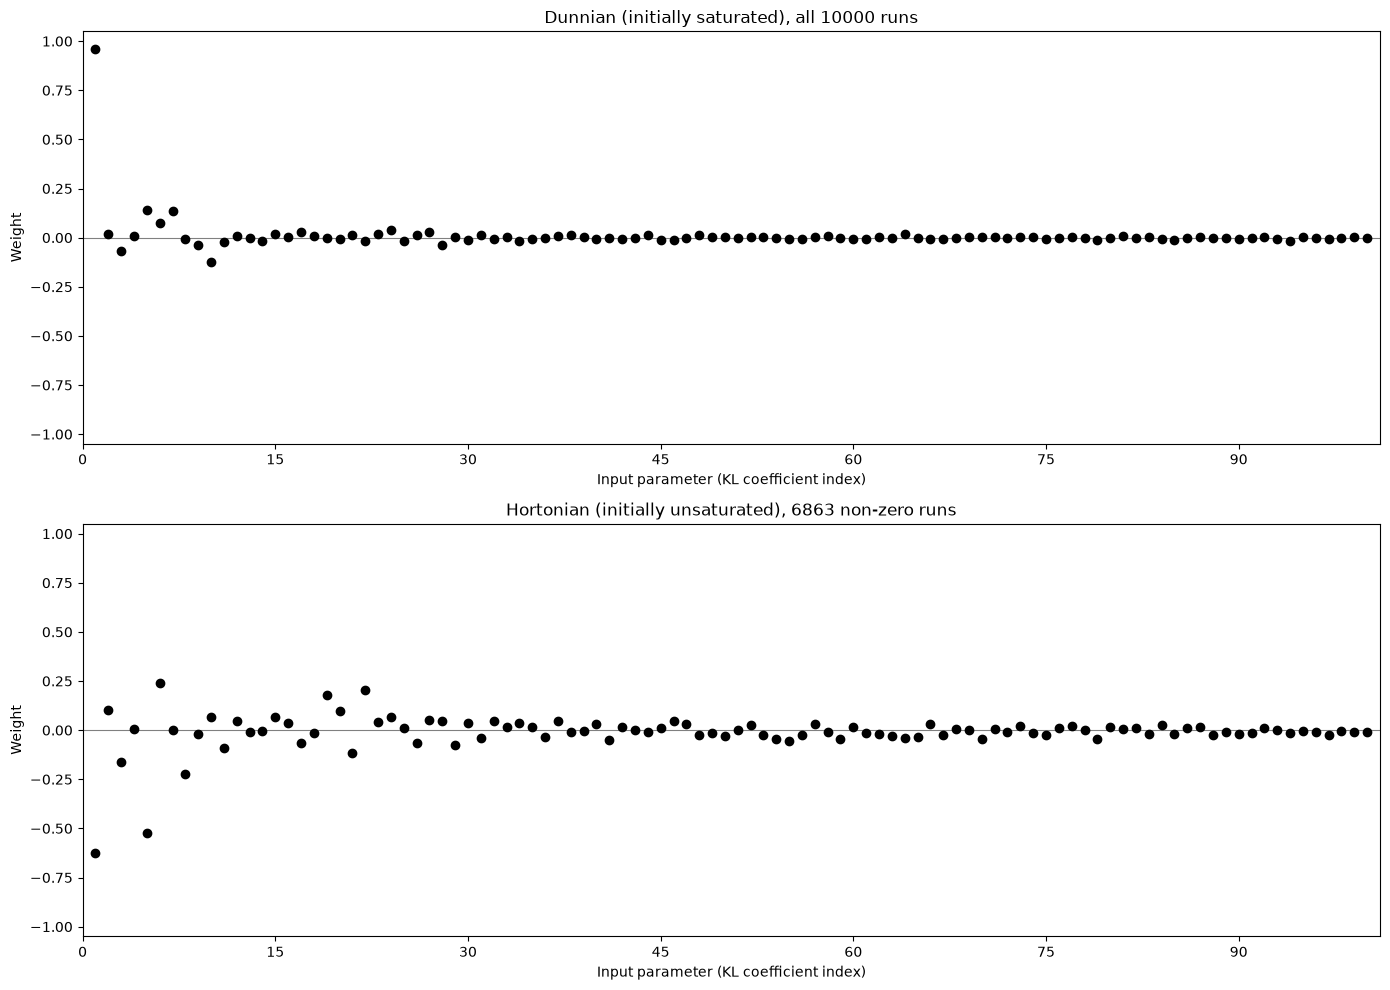

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, c in zip(axes, cases):
    ac.plotting.plot_eigenvectors(ols[c], indices=[0], ax=[ax],
                                  line_kw={'color': 'k', 'linestyle': 'none', 'markersize': 6})
    ax.set_xlim(0, m + 1)
    ax.set_xlabel('Input parameter (KL coefficient index)')
    ax.set_ylabel('Weight')
    ax.set_title(title[c] + (f', {int(nz.sum())} non-zero runs' if c == 'H' else f', all {M} runs'))
fig.tight_layout()

for c in cases:
    v = w[c]
    top = np.argsort(-np.abs(v))[:5]
    print(f'{name[c]:>9}: w_1 = {v[0]:+.3f}, w_5 = {v[4]:+.3f}; largest |weights| at '
          + ', '.join(f'x{j + 1} ({v[j]:+.3f})' for j in top)
          + f'; sum of w_i^2 over i > 30: {np.sum(v[30:]**2):.4f}')

The two scenarios differ. In the Dunnian case almost all the weight is on the first coefficient ("nearly one", [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) p. 36), and the weights beyond the 30th are close to 0: their squares sum to less than 0.01. In the Hortonian case less weight is on the first coefficient, several other low-index coefficients carry large weights, and the weights of later coefficients are small but much further from 0 than in the Dunnian case. Low-index coefficients correspond to large-scale heterogeneity and high-index coefficients to small-scale changes. So Dunnian runoff is sensitive mainly to large-scale heterogeneity, while Hortonian runoff is also sensitive to small-scale changes, as [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) concludes.

The signs follow the paper's convention. In the Dunnian case $w_1 > 0$, so runoff increases with the first coefficient. In the Hortonian case $w_1 < 0$, as in Fig. 7a of [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020): Hortonian runoff increases as the permeability carried by those modes decreases.

Next, the sufficient summary plots (Figs. 6b and 7b of [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020)): runoff against the active variable $\hat{\mathbf w}^T\mathbf x$. As in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020), the Hortonian runoff is shown on a log scale, so only the non-zero runs can appear. A third panel shows all 10,000 Hortonian runs on a linear scale, with the zero runs at the bottom (this panel is not in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020)).

Hortonian log-scale panel: 3137 of 10000 runs have zero runoff (not shown)
Dunnian:   active variable in [-4.07, 3.52]; least-squares slope of runoff on the active variable +106.6 m^3
Hortonian: active variable in [-2.89, 3.69] (non-zero runs); slope of log10(runoff) on the active variable +0.684


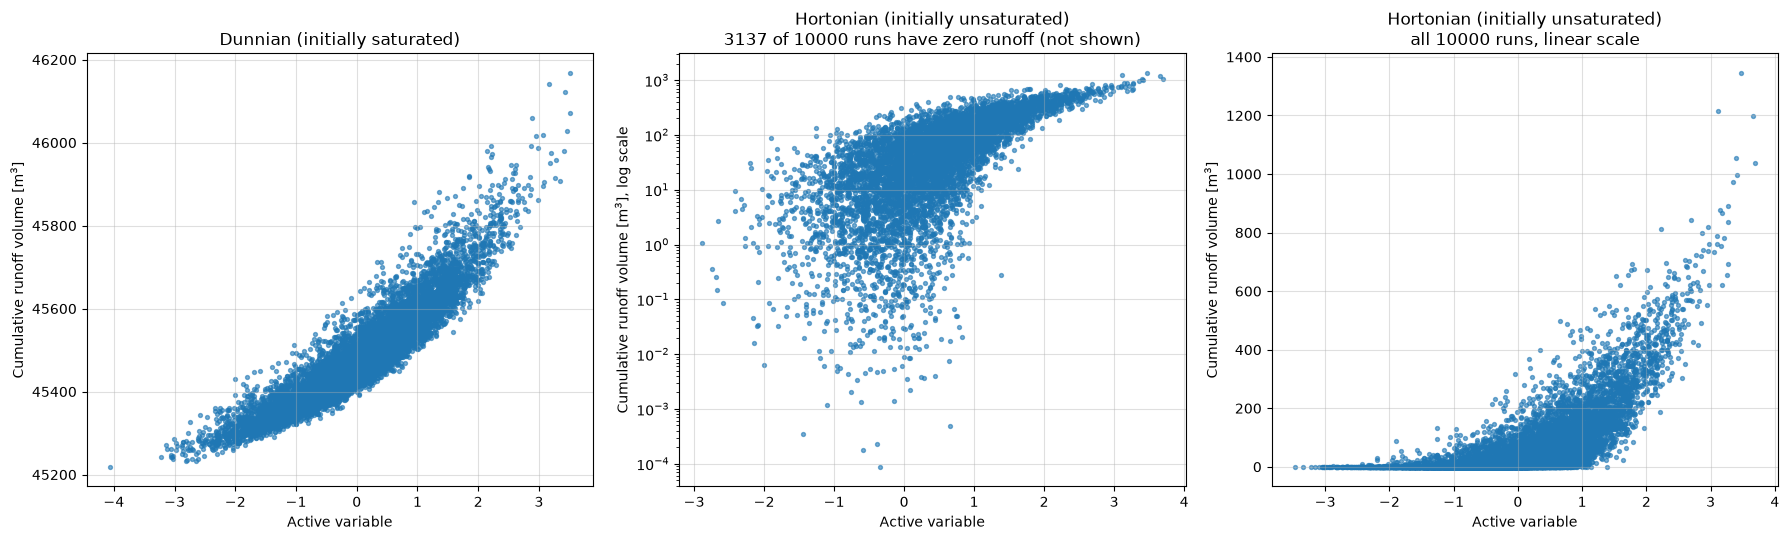

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
dots = {'s': 8, 'alpha': .6}
ac.plotting.plot_sufficient_summary(ols['D'], X=X, f=f_D, ax=axes[0], scatter_kw=dots,
                                    qoi_label='Cumulative runoff volume [m$^3$]')
axes[0].set_title(title['D'])

ac.plotting.plot_sufficient_summary(ols['H'], X=X[nz], f=f_H[nz], ax=axes[1], scatter_kw=dots,
                                    qoi_label='Cumulative runoff volume [m$^3$], log scale')
axes[1].set_yscale('log')
axes[1].set_title(f'{title["H"]}\n{n_zero} of {M} runs have zero runoff (not shown)')

ac.plotting.plot_sufficient_summary(ols['H'], X=X, f=f_H, ax=axes[2], scatter_kw=dots,
                                    qoi_label='Cumulative runoff volume [m$^3$]')
axes[2].set_title(f'{title["H"]}\nall {M} runs, linear scale')
for ax in axes:
    ax.set_xlabel('Active variable')
    ax.grid(True, alpha=.4)
fig.tight_layout()

y_D, y_H = X @ w['D'], X[nz] @ w['H']
print(f'Hortonian log-scale panel: {n_zero} of {M} runs have zero runoff (not shown)')
print(f'Dunnian:   active variable in [{y_D.min():.2f}, {y_D.max():.2f}]; '
      f'least-squares slope of runoff on the active variable {np.polyfit(y_D, f_D, 1)[0]:+.1f} m^3')
print(f'Hortonian: active variable in [{y_H.min():.2f}, {y_H.max():.2f}] (non-zero runs); '
      f'slope of log10(runoff) on the active variable {np.polyfit(y_H, np.log10(f_H[nz]), 1)[0]:+.3f}')

In both scenarios runoff increases with the active variable, as in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020). The Dunnian runoff is close to a univariate function of the active variable. The Hortonian trend is much looser, especially at low values of the active variable: one linear combination of the KL coefficients does not explain Hortonian runoff well. A higher-dimensional subspace, a different parameterization, or the zero runs, which form a separate regime, may be responsible.

**The scale of the figures in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020).** The active variables above span about $\pm 4$, as they must for standard Gaussian inputs. The summary plots of [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) span about $[-1, 1]$ (Fig. 6b) and $[-0.85, 0.9]$ (Fig. 7b), both read from the figures, and Fig. 7a shows $w_1 \approx -0.65$ and $w_5 \approx -0.50$. The next cell rescales each input column to $[-1, 1]$ by its sample minimum and maximum, refits the least-squares direction on the rescaled inputs, and compares. This rescaling is a check only; it is not used anywhere else.

In [7]:
lo, hi = X.min(0), X.max(0)
Z = 2 * (X - lo) / (hi - lo) - 1               # per-column min/max rescaling to [-1, 1]


def ols_direction(Z, f):
    a = np.linalg.lstsq(np.hstack([np.ones((len(Z), 1)), Z]), f, rcond=None)[0][1:]
    return a / np.linalg.norm(a)


paper = {'D': 'w_1 nearly one, active variable about [-1, 1]',
         'H': 'w_1 about -0.65, w_5 about -0.50, active variable about [-0.85, 0.9]'}
for c, rows, f in [('D', slice(None), f_D), ('H', nz, f_H[nz])]:
    v = ols_direction(Z[rows], f)
    y = Z[rows] @ v
    yg = X[rows] @ w[c]
    print(f'{name[c]:>9}, Gaussian scale: w_1 = {w[c][0]:+.3f}, w_5 = {w[c][4]:+.3f}, '
          f'active variable in [{yg.min():.2f}, {yg.max():.2f}]')
    print(f'{name[c]:>9}, min/max scale:  w_1 = {v[0]:+.3f}, w_5 = {v[4]:+.3f}, '
          f'active variable in [{y.min():.2f}, {y.max():.2f}]; cos with the Gaussian-scale w = {v @ w[c]:.4f}')
    print(f'{name[c]:>9}, paper (read from Fig. {6 if c == "D" else 7}): {paper[c]}')

  Dunnian, Gaussian scale: w_1 = +0.962, w_5 = +0.140, active variable in [-4.07, 3.52]
  Dunnian, min/max scale:  w_1 = +0.964, w_5 = +0.130, active variable in [-0.99, 0.92]; cos with the Gaussian-scale w = 0.9999
  Dunnian, paper (read from Fig. 6): w_1 nearly one, active variable about [-1, 1]
Hortonian, Gaussian scale: w_1 = -0.625, w_5 = -0.525, active variable in [-2.89, 3.69]
Hortonian, min/max scale:  w_1 = -0.646, w_5 = -0.501, active variable in [-0.80, 0.91]; cos with the Gaussian-scale w = 0.9992
Hortonian, paper (read from Fig. 7): w_1 about -0.65, w_5 about -0.50, active variable about [-0.85, 0.9]


The min/max rescaling reproduces the range of the paper's active variables and its Hortonian weights, so the figures of [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) appear to use it; the paper does not say. The directions on the two scales are nearly parallel, so the weights and the conclusions are the same. We keep the Gaussian scale: it is the one defined by the paper's density $\rho$, and Stein's lemma applies to it.

**Absolute and relative sensitivity.** The ranges of the two outputs are of the same order: 949 m³ for Dunnian and 1,345 m³ for Hortonian runoff (printed with the data above; [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020) says "about 1000 m³" for both). Relative to their levels they are very different. The Dunnian runoffs lie between about 45,200 and 46,200 m³; the Hortonian ones between 0 and about 1,350 m³, and 31% are exactly zero. So both scenarios have a similar absolute sensitivity to the active variable, but Hortonian runoff is far more sensitive relative to its mean.

### Extension: a global quadratic model (not in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020))

The rest of this notebook goes beyond [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020). The least-squares direction above can find only one direction. A global _quadratic_ model, $f(\mathbf x) \approx q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$, fitted by least squares, gives an estimate of the whole matrix: for $\mathbf x\sim N(\mathbf 0, \mathbf I)$,

$$
\hat{\mathbf C} = \int \nabla q\,\nabla q^T\rho\,d\mathbf x = \mathbf g\mathbf g^T + \mathbf H\mathbf H,
$$

which can reveal higher-dimensional subspaces (`estimator="qphd"`; Li [[5]](https://doi.org/10.1080/01621459.1992.10476258)). We fit it on the same runs as the least-squares directions above, on the linear runoff scale: all 10,000 Dunnian runs, and the 6,863 non-zero Hortonian runs. (The 2016 notebook fitted the Hortonian model on all 10,000 runs, zeros included.) With $m = 100$ the quadratic has 5,151 coefficients, so there are fewer than two runs per coefficient for the Dunnian fit and about 1.3 for the Hortonian fit (both printed below). The least-squares problem is still overdetermined, but barely: the fitted Hessian $\mathbf H$, and so the eigenvalues beyond the first, are noisy, the Hortonian ones most of all. The comparisons below use the least-squares directions fitted on the same runs.

Eigenvector signs are arbitrary; we orient each quadratic eigenvector so that runoff increases along it (`ac.orient(..., by="covariance")`), the same convention as $\hat{\mathbf w}$. The two fits take most of this notebook's run time, about half a minute each (printed).

In [8]:
XE = {'D': X, 'H': X[nz]}                    # the runs used in this section:
F = {'D': f_D, 'H': f_H[nz]}                 # all Dunnian runs, non-zero Hortonian runs
runs = {'D': f'all {M} runs', 'H': f'{int(nz.sum())} non-zero runs'}
n_coef = (m + 1) * (m + 2) // 2              # coefficients of a full quadratic in m inputs
quad = {}
for c in cases:
    t0 = time.perf_counter()
    q = ac.active_subspace(X=XE[c], f=F[c], space=space, estimator='qphd', qoi=f'{name[c]} runoff')
    quad[c] = ac.orient(q, by='covariance', X=XE[c], f=F[c], columns=3)
    print(f'{name[c]:>9}, {runs[c]}: {len(F[c])} runs / {n_coef} coefficients = {len(F[c]) / n_coef:.2f} runs per coefficient')
    print(f'{"":>9}  quadratic-model eigenvalues 1-4 = {np.round(quad[c].eigenvalues[:4], 2)}, '
          f'dimension chosen by the largest gap: {quad[c].n} ({time.perf_counter() - t0:.0f} s)')

  Dunnian, all 10000 runs: 10000 runs / 5151 coefficients = 1.94 runs per coefficient
           quadratic-model eigenvalues 1-4 = [12252.52   630.56   424.28   363.64], dimension chosen by the largest gap: 1 (23 s)


Hortonian, 6863 non-zero runs: 6863 runs / 5151 coefficients = 1.33 runs per coefficient
           quadratic-model eigenvalues 1-4 = [16294.24  2151.55  1833.69   701.62], dimension chosen by the largest gap: 1 (14 s)


We plot the first ten eigenvalues and two-dimensional summary plots, with the first two quadratic-model active variables as axes and the runoff as color.

  Dunnian: ratios lambda_1/lambda_2 = 19.4, lambda_2/lambda_3 = 1.49, lambda_3/lambda_4 = 1.17
Hortonian: ratios lambda_1/lambda_2 = 7.6, lambda_2/lambda_3 = 1.17, lambda_3/lambda_4 = 2.61


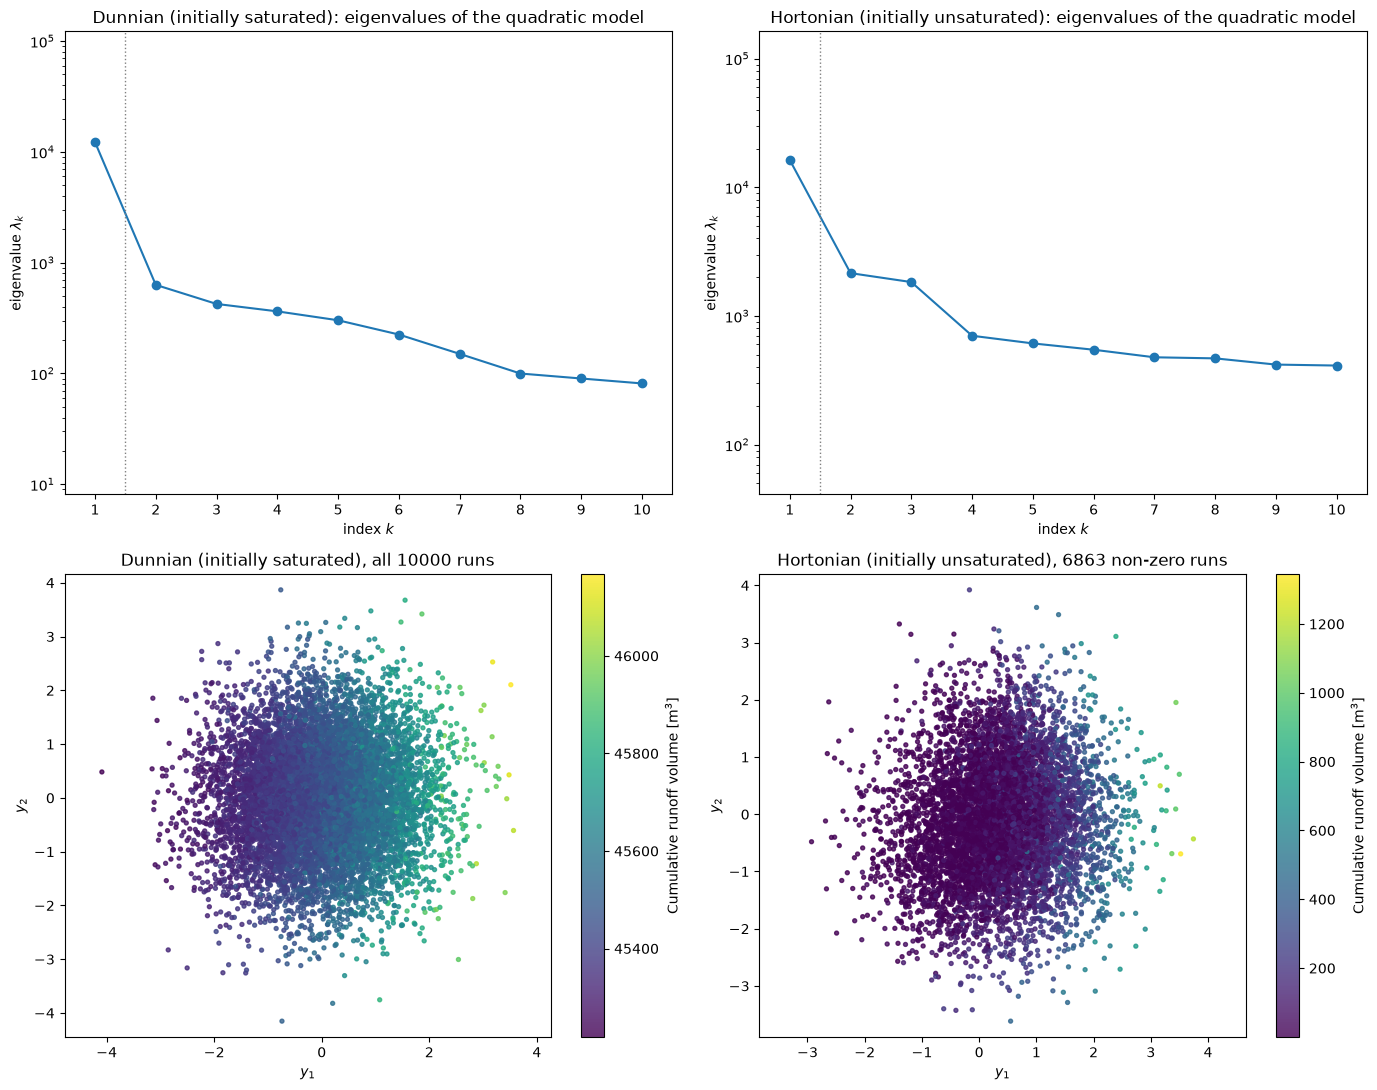

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for j, c in enumerate(cases):
    ac.plotting.plot_eigenvalues(quad[c], k_max=10, ax=axes[0, j])
    axes[0, j].set_title(f'{title[c]}: eigenvalues of the quadratic model')
    ac.plotting.plot_sufficient_summary(quad[c], X=XE[c], f=F[c], dims=2, ax=axes[1, j], scatter_kw={'s': 8},
                                        qoi_label='Cumulative runoff volume [m$^3$]')
    axes[1, j].set_title(f'{title[c]}, {runs[c]}')
fig.tight_layout()

for c in cases:
    lam = quad[c].eigenvalues
    print(f'{name[c]:>9}: ratios lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
          f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}')

There is a large gap between the first and second eigenvalues in both scenarios. In the Hortonian case there is a second gap, between the third and fourth eigenvalues, which suggests that a three-dimensional subspace may also be useful there. In the Dunnian case the eigenvalues after the first decrease gradually, with no second gap of that size (ratios printed above).

Now we compare the first quadratic-model eigenvector with the least-squares direction: the weights, and their componentwise difference.

  Dunnian: cos(w quadratic, w linear) = 0.99894; mean difference +0.0005, max |difference| 0.0173
Hortonian: cos(w quadratic, w linear) = 0.98922; mean difference +0.0011, max |difference| 0.0421


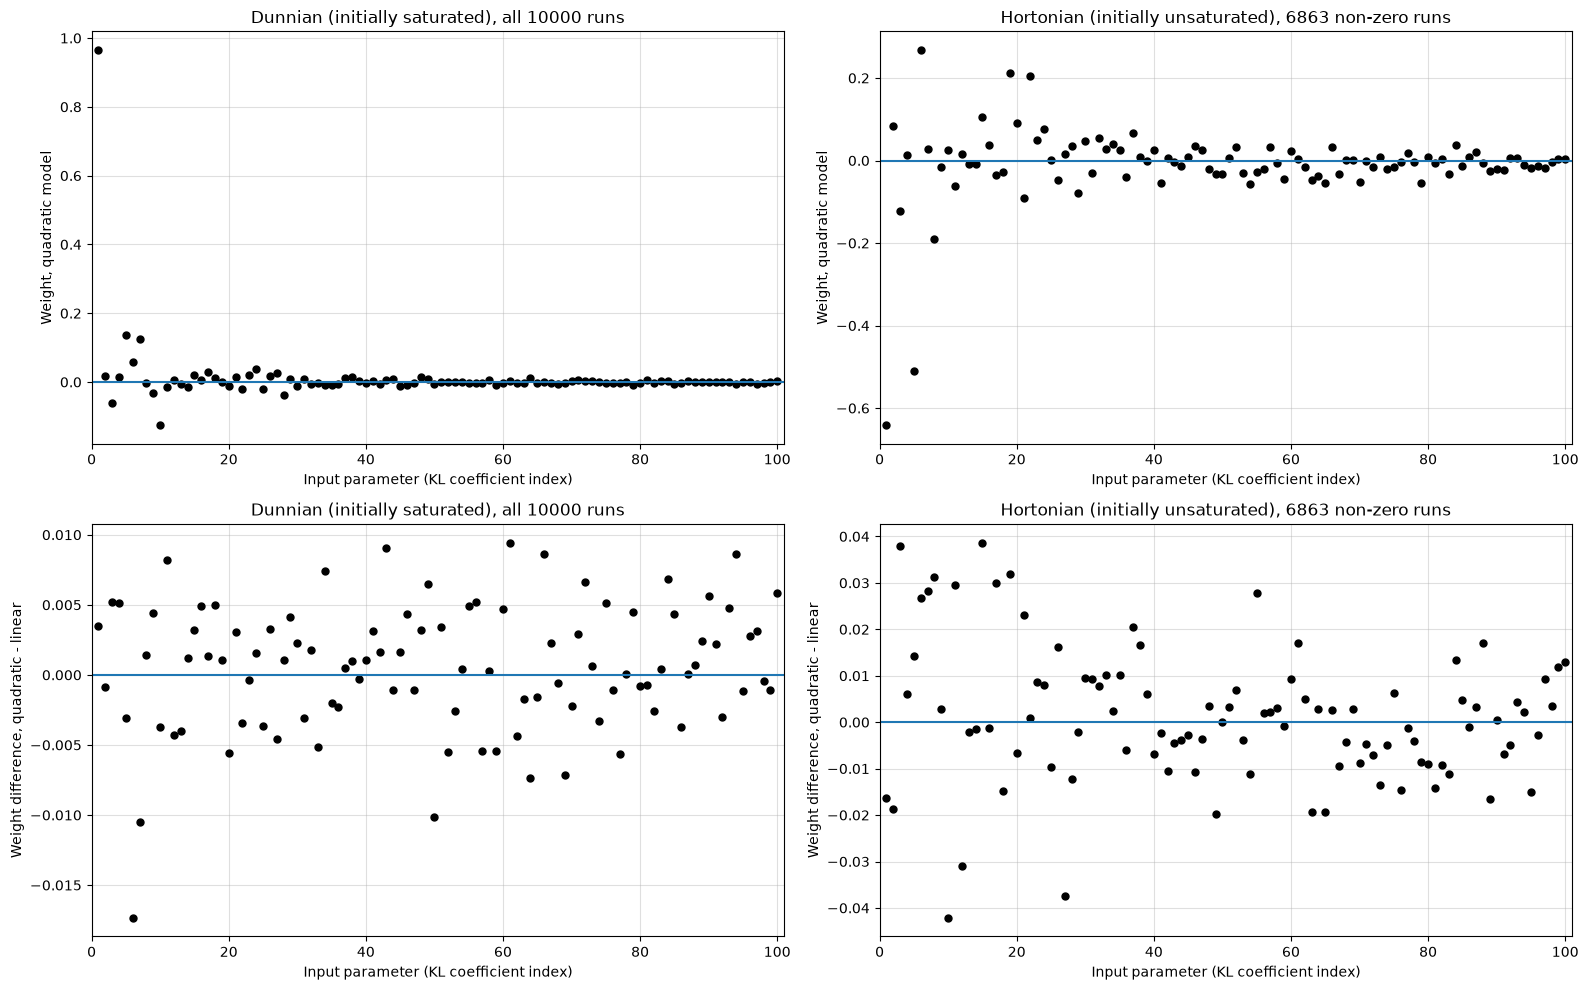

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for j, c in enumerate(cases):
    wq, wl = quad[c].W1[:, 0], ols[c].W1[:, 0]
    k = np.arange(1, m + 1)
    for ax, y, lab in [(axes[0, j], wq, 'Weight, quadratic model'),
                       (axes[1, j], wq - wl, 'Weight difference, quadratic - linear')]:
        ax.plot(k, y, 'ko', ms=5)
        ax.axhline(0, color='C0', lw=1.5)
        ax.set_xlim(0, m + 1)
        ax.grid(True, alpha=.4)
        ax.set_xlabel('Input parameter (KL coefficient index)')
        ax.set_ylabel(lab)
        ax.set_title(f'{title[c]}, {runs[c]}')
fig.tight_layout()

for c in cases:
    wq, wl = quad[c].W1[:, 0], ols[c].W1[:, 0]
    print(f'{name[c]:>9}: cos(w quadratic, w linear) = {wq @ wl:.5f}; '
          f'mean difference {np.mean(wq - wl):+.4f}, max |difference| {np.max(np.abs(wq - wl)):.4f}')

The two estimates of the first direction are very close: both point the same way, and the largest componentwise difference is 0.017 in the Dunnian case and 0.042 in the Hortonian case. The Hortonian difference is the larger, as expected from the smaller number of runs per coefficient. This agrees with the similarity of the one-dimensional summary plots.

Finally, we compare surrogates. We fit polynomials of degree 1, 2 and 3 on the active variables by least squares and compare their $R^2$. Based on the eigenvalue gaps we use a one-dimensional subspace for the Dunnian case and both a one- and a three-dimensional subspace for the Hortonian case. The least-squares direction defines a one-dimensional subspace only: the matrix $\hat{\mathbf a}\hat{\mathbf a}^T$ has rank one, and its other eigenvectors are an arbitrary basis of the orthogonal complement. (The 2016 notebook compared a three-dimensional "linear subspace" built from such arbitrary vectors with the quadratic one; those $R^2$ values depend on the eigensolver and cannot be reproduced, so we do not use them.) The table shows the in-sample $R^2$, the measure of the 2016 notebook, and next to it the leave-one-out $R^2$ (`loo_r_squared`). The cubic in three variables has 20 coefficients for thousands of runs, so the two are almost equal. The Hortonian $R^2$ values are computed on the 6,863 non-zero runs, so they are not comparable with the 2016 ones, which used all 10,000 runs; we print the 2016 values for the Dunnian case only.

In [11]:
subs = {'D': [('linear, 1-D', ols['D']), ('quadratic, 1-D', quad['D'])],
        'H': [('linear, 1-D', ols['H']), ('quadratic, 1-D', ac.with_dimension(quad['H'], 1)),
              ('quadratic, 3-D', ac.with_dimension(quad['H'], 3))]}
r2_2016 = {('D', 'linear, 1-D'): (.8473, .8771, .8776), ('D', 'quadratic, 1-D'): (.8455, .8763, .8769)}
degrees = (1, 2, 3)

surr, r2 = {}, {}
for c in cases:
    f = F[c]
    for lab, s in subs[c]:
        for d in degrees:
            g = ac.fit_surrogate(X=XE[c], f=f, subspace=s, kind='poly', degree=d)
            surr[c, lab, d] = g
            r2[c, lab, d] = (1 - np.sum(g.residuals**2) / np.sum((f - f.mean())**2), g.loo_r_squared)

for c in cases:
    print(f'R^2 for the {name[c]} case, in-sample / leave-one-out ({runs[c]}):')
    print(f'{"subspace":<26}' + ''.join(f'{["linear", "quadratic", "cubic"][d - 1] + " model":>20}' for d in degrees))
    for lab, _ in subs[c]:
        print(f'{lab:<26}' + ''.join(f'{r2[c, lab, d][0]:>11.4f} / {r2[c, lab, d][1]:.4f}' for d in degrees))
    for (cc, lab), v in r2_2016.items():
        if cc == c:
            print(f'{"2016: " + lab:<26}' + ''.join(f'{x:>11.4f}         ' for x in v))
    print()

R^2 for the Dunnian case, in-sample / leave-one-out (all 10000 runs):
subspace                          linear model     quadratic model         cubic model
linear, 1-D                    0.8473 / 0.8472     0.8771 / 0.8770     0.8776 / 0.8775
quadratic, 1-D                 0.8455 / 0.8454     0.8763 / 0.8763     0.8769 / 0.8767
2016: linear, 1-D              0.8473              0.8771              0.8776         
2016: quadratic, 1-D           0.8455              0.8763              0.8769         

R^2 for the Hortonian case, in-sample / leave-one-out (6863 non-zero runs):
subspace                          linear model     quadratic model         cubic model
linear, 1-D                    0.5319 / 0.5313     0.7233 / 0.7229     0.7397 / 0.7393
quadratic, 1-D                 0.5171 / 0.5165     0.7278 / 0.7274     0.7497 / 0.7494
quadratic, 3-D                 0.5224 / 0.5214     0.8280 / 0.8270     0.8742 / 0.8730



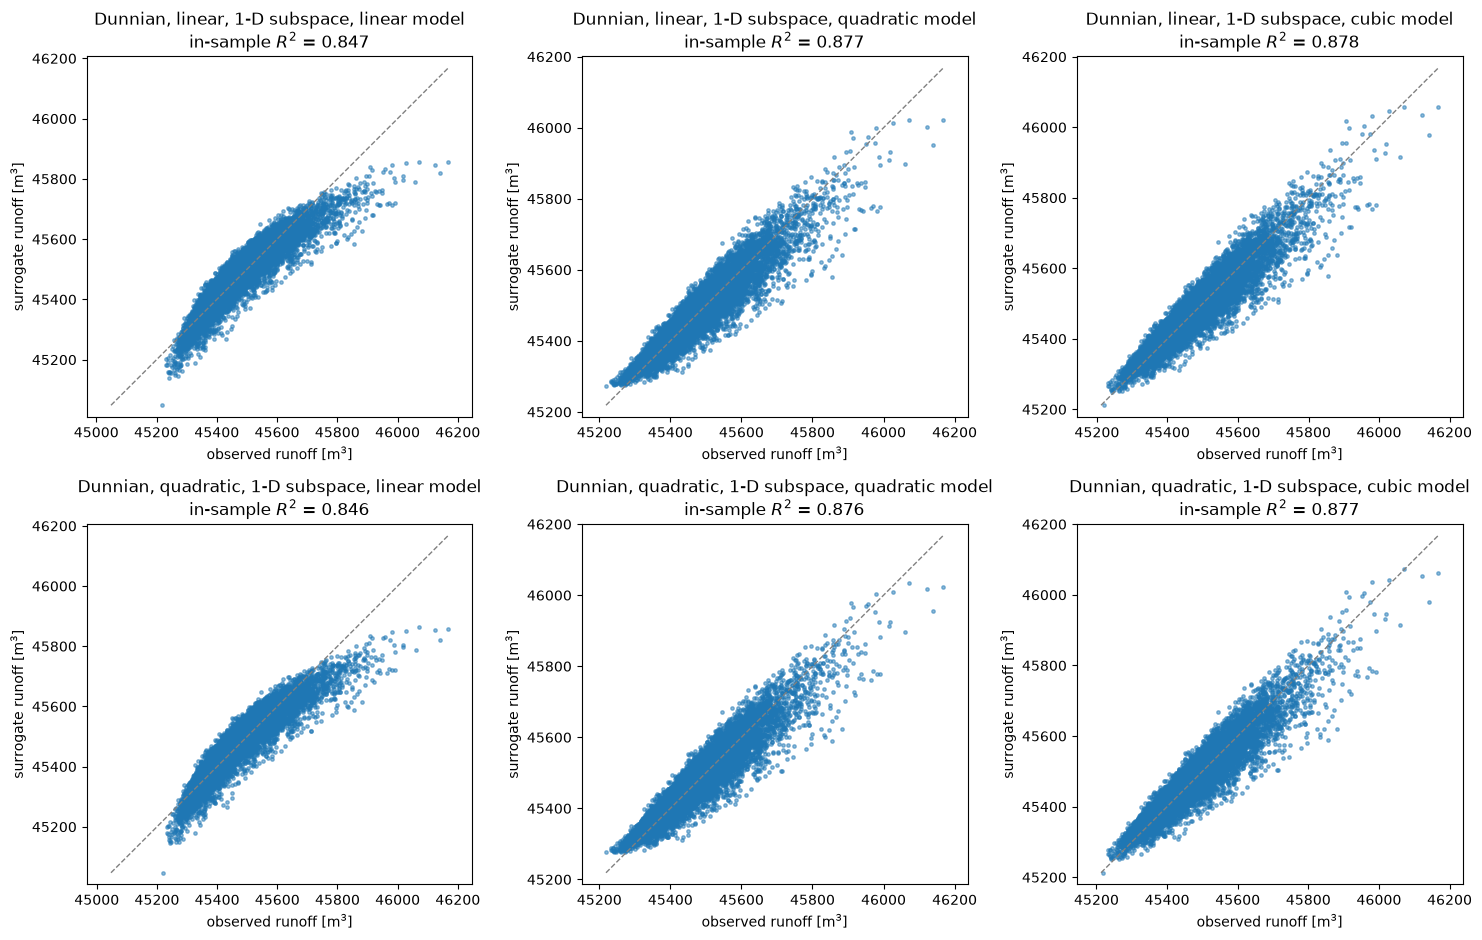

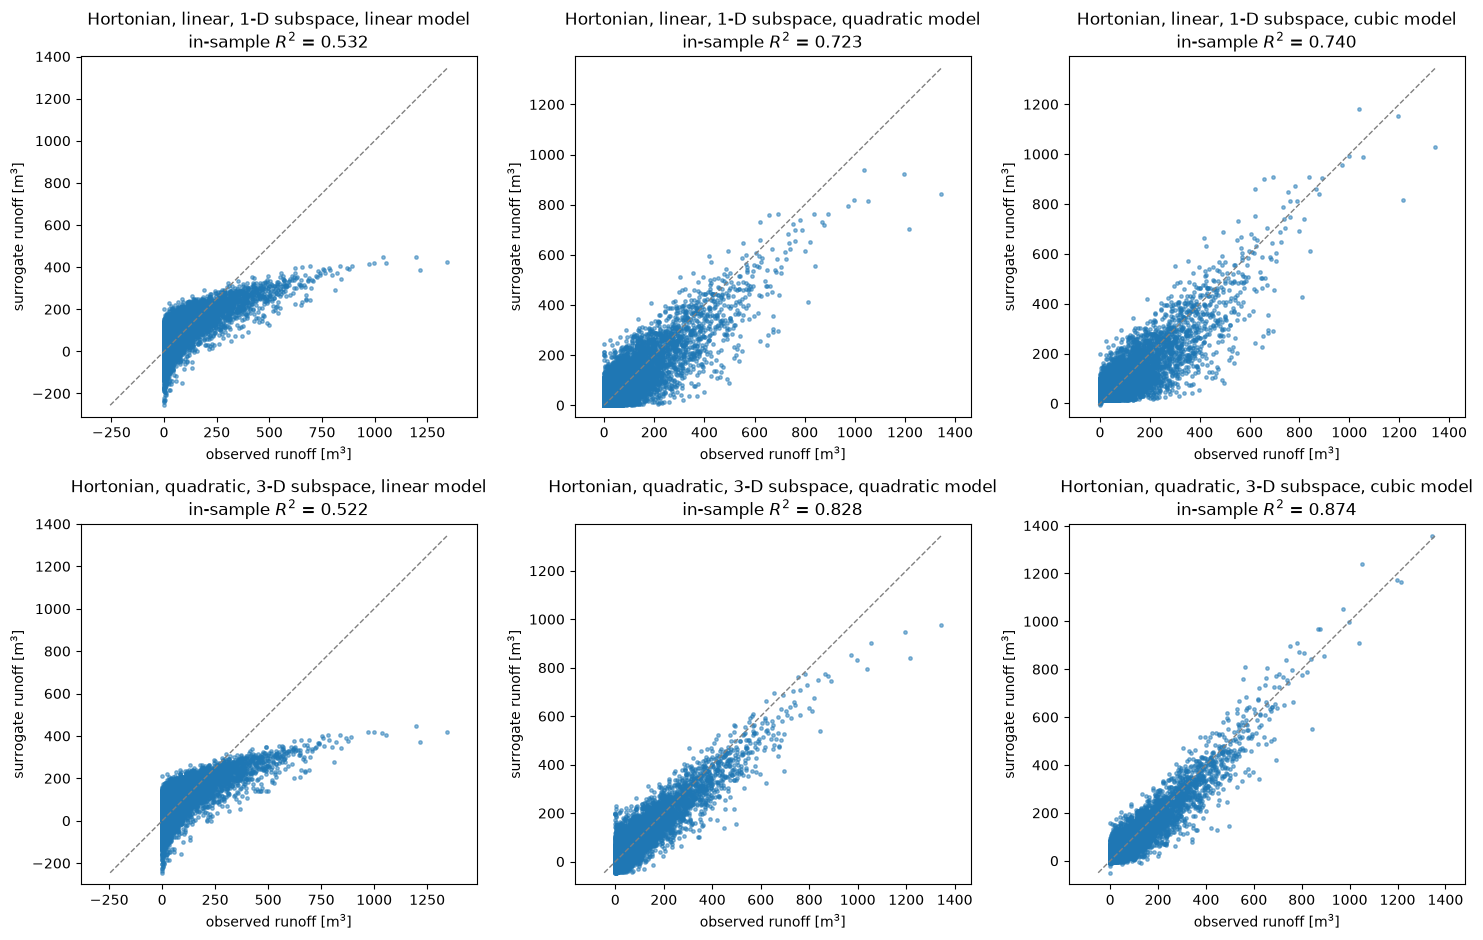

In [12]:
for c, rows in [('D', subs['D']), ('H', [subs['H'][0], subs['H'][2]])]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
    for i, (lab, _) in enumerate(rows):
        for j, d in enumerate(degrees):
            ax = axes[i, j]
            ac.plotting.plot_surrogate_fit(surr[c, lab, d], X=XE[c], f=F[c], ax=ax, qoi_label='runoff [m$^3$]',
                                           scatter_kw={'s': 6, 'alpha': .5})
            ax.set_title(f'{name[c]}, {lab} subspace, {["linear", "quadratic", "cubic"][d - 1]} model\n'
                         f'in-sample $R^2$ = {r2[c, lab, d][0]:.3f}')
    fig.tight_layout()

In the Dunnian case the quadratic model's subspace does not help: the fits and the $R^2$ values are almost the same for both one-dimensional subspaces, and a quadratic in the active variable is enough. In the Hortonian case the one-dimensional subspaces of the two methods also give almost the same $R^2$. The three-dimensional quadratic-model subspace improves the quadratic and cubic surrogates markedly: $R^2$ rises from 0.72 to 0.83 for the quadratic surrogate and from 0.74 to 0.87 for the cubic surrogate, compared with the one-dimensional least-squares subspace. The linear surrogate does not improve, as expected: its best direction is the least-squares direction itself.

The in-sample $R^2$ values in both Dunnian rows equal those printed by the 2016 notebook. The 2016 Hortonian table is not comparable: it used all 10,000 runs, zeros included, and its "linear subspace" row used the arbitrary three-dimensional basis described above. Its text compared the quadratic-model subspace with that row.

### Conclusions

Active subspaces characterize the sensitivity of runoff to heterogeneity in subsurface permeability at much less cost than a parameter study on the full 100-dimensional input space. This could be used for optimization or to constrain an inverse problem. The study is a proof of concept: only the permeability varies, only a single direction is estimated in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020), and the Dunnian and Hortonian mechanisms are studied separately. Further work could vary other model parameters, use gradients (from finite differences or an adjoint) to find higher-dimensional subspaces, and study both runoff mechanisms together.

The global quadratic model, an extension not in [[1]](https://doi.org/10.1016/j.advwatres.2016.03.020), gives first eigenvectors very close to the least-squares directions, and it can find higher-dimensional subspaces. It finds no evidence of one in the Dunnian case. In the Hortonian case its eigenvalues suggest a three-dimensional subspace, and quadratic and cubic surrogates on that subspace fit markedly better. The quadratic model costs more to fit and needs many runs per input dimension, but it gives more flexibility when one direction is not enough.

In [13]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 50 s
